# TP Integrador de Aprendizaje Automático
## Pérdida económica por maquinaria vial bajo custodia: regresión + alerta crítica

> **Aviso importante:** los datos de este trabajo son **SIMULADOS** (generados por código con semilla fija).
> Las métricas miden el desempeño **dentro de la simulación** y **no** prueban capacidad predictiva sobre
> pérdidas reales de maquinaria. Los valores de referencia, factores y umbral son **supuestos didácticos**.

**Cómo ejecutar:** `Kernel > Restart & Run All`. El notebook genera los datos, los controla, entrena,
evalúa y guarda los modelos oficiales en `modelos/`. La aplicación Flask solamente carga esos archivos.

**Índice**
1. Problema, momento de predicción y umbral
2. Generación del dataset simulado (crudo)
3. Controles de calidad y dataset preparado
4. Fuga de información y variables predictoras
5. Partición train / validation / test
6. Baselines
7. Regresión (selección con validación)
8. Clasificación (selección con validación y costos)
9. Evaluación final en test (una sola vez)
10. Comparación integrada: clasificador directo vs regresión + umbral
11. Guardado de modelos y verificación

## 1. Problema, momento de predicción y umbral

**Problema.** Un organismo que custodia maquinaria vial inmovilizada necesita priorizar qué equipos
atender primero (reasignar, reparar o rematar), porque cada mes de inactividad genera una pérdida económica.

**Usuario y decisión.** El área administrativa que gestiona la custodia decide qué equipos revisar con urgencia.

**Momento exacto de la predicción.** Al realizar la **inspección inicial** del equipo, con una proyección de
los meses de inactividad acumulados al momento de la consulta. Solo se usan datos conocidos en ese momento.

| Salida | Definición |
|---|---|
| Regresión | `perdida_economica_usd`: pérdida económica estimada en USD |
| Clasificación | `perdida_critica = 1` si `perdida_economica_usd >= 100.000` USD, y `0` en caso contrario |

**Umbral (USD 100.000).** Es un **supuesto didáctico**: representa un nivel de pérdida a partir del cual el
equipo pasa a revisión prioritaria. Se aplica con `>=` en **todos** los componentes (datos, evaluación, app e informe).

**Falsos positivos / falsos negativos.**
- *Falso negativo (FN)*: el sistema dice "no crítico" pero la pérdida era crítica → un equipo urgente queda sin atender.
- *Falso positivo (FP)*: el sistema dice "crítico" pero no lo era → se hace una revisión innecesaria.

In [1]:
import sys, json, math, platform, warnings
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import joblib
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix)

# ----- Raíz del proyecto (funciona ejecutando desde notebooks/ o desde la raíz) -----
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_DATOS = RAIZ / "datos"
DIR_MODELOS = RAIZ / "modelos"
DIR_DATOS.mkdir(exist_ok=True)
DIR_MODELOS.mkdir(exist_ok=True)

# ----- Parámetros únicos del proyecto (fuente de verdad) -----
SEMILLA = 42
UMBRAL = 100_000          # USD. Regla única: perdida_critica = (perdida >= UMBRAL)
ANIO_REFERENCIA = 2026    # año del momento de predicción
ANIO_MIN, ANIO_MAX = 2000, 2026
MESES_MIN, MESES_MAX = 1, 120
N_BASE = 2500

# Costos relativos de decisión (SUPUESTOS experimentales, no costos observados)
COSTO_FN = 5
COSTO_FP = 1

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 160)

print("Python      :", platform.python_version())
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib      :", joblib.__version__)
print("matplotlib  :", matplotlib.__version__)
print("Semilla     :", SEMILLA, "| Umbral:", UMBRAL, "| Raíz:", RAIZ)

Python      : 3.12.3
numpy       : 2.4.4
pandas      : 3.0.2
scikit-learn: 1.8.0
joblib      : 1.5.3
matplotlib  : 3.10.8
Semilla     : 42 | Umbral: 100000 | Raíz: /home/claude/work/proyecto_corregido


## 2. Generación del dataset simulado (crudo)

**Cada fila** representa un equipo de maquinaria vial inspeccionado, con sus datos de ingreso y los meses de inactividad.

**Fórmula de la pérdida (supuestos didácticos, todos los predictores influyen):**

```
antiguedad     = 2026 - anio_fabricacion
valor_actual   = valor_ref[tipo_equipo] * 0.96 ** antiguedad          (depreciación 4 % anual)
perdida_USD    = valor_actual * 0.012 * meses_inactividad
                 * mult_estado[estado_motor] * mult_provincia[provincia]
                 * ruido_multiplicativo + ruido_aditivo
ruido_multiplicativo ~ Lognormal(0, 0.10)      ruido_aditivo ~ Normal(0, 5000)      perdida >= 0
```

| Parámetro | Valores (supuestos) |
|---|---|
| `valor_ref` (USD) | Motoniveladora 250.000 · Excavadora 220.000 · Retroexcavadora 150.000 · Cargadora frontal 180.000 · Rodillo compactador 120.000 · Topadora 300.000 |
| `mult_estado` | Funcional 1,00 · Requiere_Reparacion 1,25 · Averia_Grave 1,50 |
| `mult_provincia` | Buenos Aires 1,00 · Córdoba 0,95 · Santa Fe 0,95 · Mendoza 1,05 · Salta 1,10 |

La pérdida se calcula con los valores **verdaderos**. Después se simulan problemas de carga de datos
(faltantes, duplicados y valores imposibles) para que exista un trabajo real de limpieza.

**Qué NO representa:** no modela mercado real de alquileres, cotizaciones, ni costos judiciales; no incluye
variables como horas de uso o ubicación exacta. Es solo un entorno controlado para practicar el flujo completo.

In [2]:
rng = np.random.default_rng(SEMILLA)

TIPOS = ["Motoniveladora", "Excavadora", "Retroexcavadora", "Cargadora frontal", "Rodillo compactador", "Topadora"]
PROVINCIAS = ["Buenos Aires", "Córdoba", "Santa Fe", "Mendoza", "Salta"]
ESTADOS = ["Funcional", "Requiere_Reparacion", "Averia_Grave"]

VALOR_REF = {"Motoniveladora": 250_000, "Excavadora": 220_000, "Retroexcavadora": 150_000,
             "Cargadora frontal": 180_000, "Rodillo compactador": 120_000, "Topadora": 300_000}
MULT_ESTADO = {"Funcional": 1.00, "Requiere_Reparacion": 1.25, "Averia_Grave": 1.50}
MULT_PROV = {"Buenos Aires": 1.00, "Córdoba": 0.95, "Santa Fe": 0.95, "Mendoza": 1.05, "Salta": 1.10}
TASA_MENSUAL = 0.012
DEPRECIACION_ANUAL = 0.04

df_real = pd.DataFrame({
    "tipo_equipo": rng.choice(TIPOS, N_BASE),
    "provincia": rng.choice(PROVINCIAS, N_BASE),
    "meses_inactividad": rng.integers(MESES_MIN, MESES_MAX + 1, N_BASE),
    "anio_fabricacion": rng.integers(ANIO_MIN, ANIO_MAX + 1, N_BASE),
    "estado_motor": rng.choice(ESTADOS, N_BASE, p=[0.30, 0.40, 0.30]),
})
df_real.insert(0, "id_registro", [f"EQ-{i:04d}" for i in range(1, N_BASE + 1)])

antiguedad = ANIO_REFERENCIA - df_real["anio_fabricacion"]
valor_actual = df_real["tipo_equipo"].map(VALOR_REF) * (1 - DEPRECIACION_ANUAL) ** antiguedad
perdida = (valor_actual * TASA_MENSUAL * df_real["meses_inactividad"]
           * df_real["estado_motor"].map(MULT_ESTADO) * df_real["provincia"].map(MULT_PROV)
           * rng.lognormal(0, 0.10, N_BASE) + rng.normal(0, 5000, N_BASE))
df_real["perdida_economica_usd"] = perdida.clip(lower=0).round(2)
df_real["perdida_critica"] = (df_real["perdida_economica_usd"] >= UMBRAL).astype("int8")

# ----- Problemas de carga simulados (se aplican DESPUÉS de calcular el objetivo) -----
df_crudo = df_real.copy()
idx = rng.choice(df_crudo.index, 60, replace=False)
df_crudo.loc[idx[:50], "meses_inactividad"] = np.nan                       # 50 faltantes
df_crudo.loc[idx[50:55], "meses_inactividad"] = -3                         # 5 valores imposibles (negativos)
df_crudo.loc[idx[55:60], "meses_inactividad"] = 999                        # 5 valores imposibles (fuera de rango)
duplicadas = df_crudo.sample(20, random_state=SEMILLA)                     # 20 duplicados exactos
df_crudo = pd.concat([df_crudo, duplicadas], ignore_index=True)

ruta_crudo = DIR_DATOS / "dataset_maquinaria_crudo.csv"
df_crudo.to_csv(ruta_crudo, index=False)
print(f"Dataset CRUDO guardado en: {ruta_crudo.relative_to(RAIZ)}  ->  {df_crudo.shape[0]} filas x {df_crudo.shape[1]} columnas")
display(df_crudo.head())

Dataset CRUDO guardado en: datos/dataset_maquinaria_crudo.csv  ->  2520 filas x 8 columnas


,id_registro,tipo_equipo,provincia,meses_inactividad,anio_fabricacion,estado_motor,perdida_economica_usd,perdida_critica
0,EQ-0001,Motoniveladora,Mendoza,24.0000,2023,Funcional,"68,983.6200",0
1,EQ-0002,Rodillo compactador,Buenos Aires,5.0000,2002,Requiere_Reparacion,"6,005.2200",0
2,EQ-0003,Cargadora frontal,Mendoza,76.0000,2020,Averia_Grave,"198,916.2400",1
3,EQ-0004,Retroexcavadora,Buenos Aires,82.0000,2013,Funcional,"77,686.1000",0
4,EQ-0005,Retroexcavadora,Buenos Aires,93.0000,2020,Funcional,"122,083.3400",1


## 3. Controles de calidad y dataset preparado

**Política de limpieza (decisiones documentadas):**

| Problema | Acción | Motivo |
|---|---|---|
| Duplicados completos | Eliminar | Un mismo equipo no debe contarse dos veces |
| Valores imposibles (`meses_inactividad` fuera de 1–120) | Eliminar la fila | No se puede saber el valor real |
| Faltantes en `meses_inactividad` | Eliminar la fila | Es la variable más importante; imputar la mediana agregaría un valor inventado y, si se calculara con todos los datos, filtraría información de test. Se pierde solo ~2 % de los datos y se mantienen más de 2.000 registros |

El archivo **preparado no contiene nulos**. El CSV crudo se conserva aparte para dejar evidencia del proceso.

In [3]:
df = pd.read_csv(ruta_crudo)
registro = []   # bitácora de limpieza: (control, hallazgo, acción)

print("=== CONTROLES DE CALIDAD (dataset crudo) ===")
print("Dimensiones iniciales:", df.shape)
print("\nTipos de datos:\n", df.dtypes.to_string())
print("\nValores faltantes por columna:\n", df.isna().sum().to_string())

n_dup_completos = int(df.duplicated().sum())
n_dup_id = int(df["id_registro"].duplicated().sum())
print("\nDuplicados completos:", n_dup_completos, "| Duplicados por id_registro:", n_dup_id)

# Categorías desconocidas
for col, validas in [("tipo_equipo", TIPOS), ("provincia", PROVINCIAS), ("estado_motor", ESTADOS)]:
    desconocidas = sorted(set(df[col].dropna().unique()) - set(validas))
    print(f"Categorías desconocidas en {col}:", desconocidas if desconocidas else "ninguna")

# Rangos
print("\nRangos observados:")
print(df[["meses_inactividad", "anio_fabricacion", "perdida_economica_usd"]].describe().loc[["min", "max"]].to_string())
imposibles_meses = df["meses_inactividad"].notna() & ~df["meses_inactividad"].between(MESES_MIN, MESES_MAX)
imposibles_anio = ~df["anio_fabricacion"].between(ANIO_MIN, ANIO_MAX)
print("Meses fuera de [1,120]:", int(imposibles_meses.sum()), "| Años fuera de [2000,2026]:", int(imposibles_anio.sum()))

print("\nDistribución de la clase ANTES de limpiar:")
print(df["perdida_critica"].value_counts(normalize=True).sort_index().round(4).to_string())

# ----- Limpieza -----
n0 = len(df)
df = df.drop_duplicates()
registro.append(("Duplicados completos", n_dup_completos, "Eliminados"))
n1 = len(df)
df = df[~(df["meses_inactividad"].notna() & ~df["meses_inactividad"].between(MESES_MIN, MESES_MAX))]
registro.append(("Valores imposibles en meses_inactividad", n1 - len(df), "Filas eliminadas"))
n2 = len(df)
df = df.dropna(subset=["meses_inactividad"])
registro.append(("Faltantes en meses_inactividad", n2 - len(df), "Filas eliminadas"))

df = df.astype({"meses_inactividad": "int64", "anio_fabricacion": "int64", "perdida_critica": "int8"}).reset_index(drop=True)

# Verificaciones: el objetivo debe cumplir la regla única con >=
assert df.isna().sum().sum() == 0, "El dataset preparado no debe tener nulos"
assert not df["id_registro"].duplicated().any()
assert (df["perdida_critica"] == (df["perdida_economica_usd"] >= UMBRAL).astype("int8")).all()
assert df["meses_inactividad"].between(MESES_MIN, MESES_MAX).all()

ruta_preparado = DIR_DATOS / "dataset_maquinaria_preparado.csv"
df.to_csv(ruta_preparado, index=False)

print("\n=== RESUMEN DE LIMPIEZA ===")
display(pd.DataFrame(registro, columns=["Control", "Filas afectadas", "Acción"]))
print(f"Filas: {n0} -> {len(df)}  |  Nulos en preparado: {int(df.isna().sum().sum())}")
print("Preparado guardado en:", ruta_preparado.relative_to(RAIZ))
assert len(df) >= 2000, "Se requieren al menos 2000 registros"

print("\nDistribución de la clase DESPUÉS de limpiar:")
print(df["perdida_critica"].value_counts(normalize=True).sort_index().round(4).to_string())
print("\nEstadísticos de la pérdida (USD):")
print(df["perdida_economica_usd"].describe().round(2).to_string())

=== CONTROLES DE CALIDAD (dataset crudo) ===
Dimensiones iniciales: (2520, 8)

Tipos de datos:
 id_registro                  str
tipo_equipo                  str
provincia                    str
meses_inactividad        float64
anio_fabricacion           int64
estado_motor                 str
perdida_economica_usd    float64
perdida_critica            int64

Valores faltantes por columna:
 id_registro               0
tipo_equipo               0
provincia                 0
meses_inactividad        51
anio_fabricacion          0
estado_motor              0
perdida_economica_usd     0
perdida_critica           0

Duplicados completos: 20 | Duplicados por id_registro: 20
Categorías desconocidas en tipo_equipo: ninguna
Categorías desconocidas en provincia: ninguna
Categorías desconocidas en estado_motor: ninguna

Rangos observados:
     meses_inactividad  anio_fabricacion  perdida_economica_usd
min            -3.0000        2,000.0000                 0.0000
max           999.0000        2,0

,Control,Filas afectadas,Acción
0,Duplicados completos,20,Eliminados
1,Valores imposibles en meses_inactividad,10,Filas eliminadas
2,Faltantes en meses_inactividad,50,Filas eliminadas


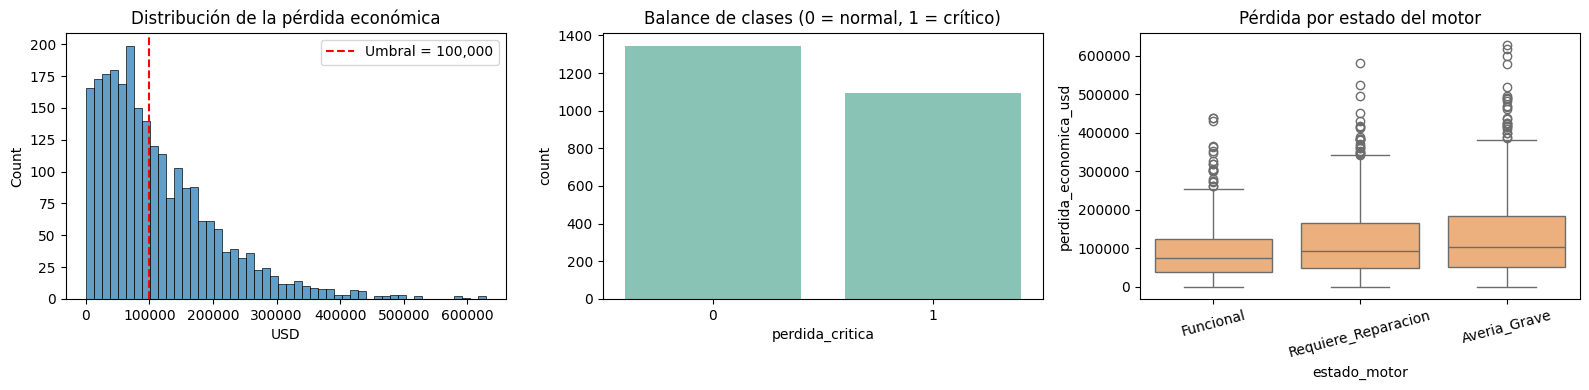

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["perdida_economica_usd"], bins=50, ax=ax[0], color="#2c7fb8")
ax[0].axvline(UMBRAL, color="red", ls="--", label=f"Umbral = {UMBRAL:,}")
ax[0].set_title("Distribución de la pérdida económica"); ax[0].set_xlabel("USD"); ax[0].legend()
sns.countplot(x="perdida_critica", data=df, ax=ax[1], color="#7fcdbb")
ax[1].set_title("Balance de clases (0 = normal, 1 = crítico)")
sns.boxplot(x="estado_motor", y="perdida_economica_usd", data=df, ax=ax[2], color="#fdae6b")
ax[2].set_title("Pérdida por estado del motor"); ax[2].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

**Interpretación.** La pérdida tiene una cola larga hacia la derecha (pocos equipos con pérdidas muy altas). El umbral
de USD 100.000 deja una proporción de casos críticos cercana a la mitad, por lo que las clases están **razonablemente
balanceadas** y el *accuracy* de un clasificador que siempre diga "no crítico" **no** es engañosamente alto. La pérdida
crece con el deterioro del motor, como establece la simulación.

## 4. Fuga de información y variables predictoras

**Momento de la predicción:** inspección inicial del equipo (con los meses de inactividad al momento de la consulta).

| Variable | Disponible al predecir | Cómo se obtiene |
|---|---|---|
| `tipo_equipo` | Sí | Se identifica al ingresar el bien |
| `provincia` | Sí | Jurisdicción donde está custodiado |
| `meses_inactividad` | Sí | Meses desde el último uso hasta la fecha de la consulta |
| `anio_fabricacion` | Sí | Dato de la documentación del equipo |
| `estado_motor` | Sí | Resultado de la inspección inicial |

**Variables excluidas de los predictores:**
- `perdida_economica_usd` y `perdida_critica`: son los objetivos (usarlas sería fuga directa).
- `id_registro`: identificador sin valor predictivo.

**Limitación:** como los datos son simulados, las relaciones entre predictores y pérdida son las que definió la fórmula
del apartado 2; no se deben interpretar como relaciones reales.

## 5. Partición train / validation / test (60 / 20 / 20)

El test se separa **antes** de comparar modelos y se mantiene aislado. Se usan **los mismos casos** para regresión y
clasificación. La selección de modelos se hace solo con validación.

In [5]:
PREDICTORES = ["tipo_equipo", "provincia", "meses_inactividad", "anio_fabricacion", "estado_motor"]
COL_NUM = ["meses_inactividad", "anio_fabricacion"]
COL_CAT = ["tipo_equipo", "provincia", "estado_motor"]

X = df[PREDICTORES]
y_reg = df["perdida_economica_usd"]
y_clf = df["perdida_critica"]

X_temp, X_test, yr_temp, yr_test, yc_temp, yc_test = train_test_split(
    X, y_reg, y_clf, test_size=0.20, random_state=SEMILLA, stratify=y_clf)
X_train, X_val, yr_train, yr_val, yc_train, yc_val = train_test_split(
    X_temp, yr_temp, yc_temp, test_size=0.25, random_state=SEMILLA, stratify=yc_temp)

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}  (total {len(X)})")
print("Proporción de clase crítica -> train: %.3f | val: %.3f | test: %.3f"
      % (yc_train.mean(), yc_val.mean(), yc_test.mean()))
assert not (set(X_train.index) & set(X_test.index)) and not (set(X_val.index) & set(X_test.index))


def crear_preprocesador():
    # El escalado y la codificación viven DENTRO del Pipeline y se ajustan solo con entrenamiento.
    return ColumnTransformer([
        ("num", StandardScaler(), COL_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COL_CAT),
    ])

Train: 1464 | Validation: 488 | Test: 488  (total 2440)
Proporción de clase crítica -> train: 0.448 | val: 0.449 | test: 0.449


## 6 y 7. Baselines y regresión (selección con validación)

Se comparan: `DummyRegressor` (baseline), `DecisionTreeRegressor` (profundidades 3, 5 y 10) y `KNeighborsRegressor`
(k = 5 y 15) con `StandardScaler` dentro del Pipeline. La métrica de selección es el **MAE en validación**.

In [6]:
def metricas_reg(y_true, y_pred):
    return {"MAE (USD)": mean_absolute_error(y_true, y_pred),
            "RMSE (USD)": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}


def pipe(modelo):
    return Pipeline([("prep", crear_preprocesador()), ("model", modelo)])


modelos_reg = {
    "Dummy (media)": DummyRegressor(strategy="mean"),
    "Árbol prof=3": pipe(DecisionTreeRegressor(max_depth=3, random_state=SEMILLA)),
    "Árbol prof=5": pipe(DecisionTreeRegressor(max_depth=5, random_state=SEMILLA)),
    "Árbol prof=10": pipe(DecisionTreeRegressor(max_depth=10, random_state=SEMILLA)),
    "KNN k=5": pipe(KNeighborsRegressor(n_neighbors=5)),
    "KNN k=15": pipe(KNeighborsRegressor(n_neighbors=15)),
}

filas = []
for nombre, m in modelos_reg.items():
    m.fit(X_train, yr_train)
    filas.append({"Modelo": nombre, **metricas_reg(yr_val, m.predict(X_val))})
tabla_reg_val = pd.DataFrame(filas).set_index("Modelo")

print("--- REGRESIÓN: resultados en VALIDACIÓN ---")
display(tabla_reg_val)

candidatos = tabla_reg_val.drop(index="Dummy (media)")
nombre_reg = candidatos["MAE (USD)"].idxmin()
print(f"\nRegresor seleccionado (menor MAE en validación): {nombre_reg}")

--- REGRESIÓN: resultados en VALIDACIÓN ---

Regresor seleccionado (menor MAE en validación): KNN k=15


,MAE (USD),RMSE (USD),R2
Modelo,,,
Dummy (media),"68,849.2218","86,833.1676",-0.0048
Árbol prof=3,"36,431.4537","52,205.9068",0.6368
Árbol prof=5,"29,831.9906","42,575.8503",0.7584
Árbol prof=10,"19,954.0281","29,097.9712",0.8872
KNN k=5,"22,493.1972","31,929.0768",0.8641
KNN k=15,"18,857.5417","26,590.4280",0.9058


**Interpretación de la tabla de validación.** Cada fila muestra cuánto se equivoca, en promedio, cada modelo sobre
casos que no vio durante el ajuste. El `DummyRegressor` siempre predice la media y marca el piso a superar: un
modelo útil debe tener MAE y RMSE menores y un R² claramente positivo. Entre los árboles, una profundidad muy
baja no captura las interacciones (tipo × meses × estado) y una muy alta puede sobreajustar; por eso se comparan
varias. El modelo se elige con validación, **no** con test.

## 8. Clasificación (selección con validación y costos)

Se comparan: `DummyClassifier`, `DecisionTreeClassifier` (profundidades 3, 5 y 10), `KNeighborsClassifier`
(k = 5 y 15, con `StandardScaler` en el Pipeline) y `GaussianNB`.

**Esquema de costos (supuesto experimental, no un costo observado):**

| Error | Costo relativo | Criterio |
|---|---|---|
| Falso negativo (FN) | **5** | Un equipo crítico sin atender sigue acumulando pérdida mes a mes |
| Falso positivo (FP) | **1** | Una revisión innecesaria cuesta tiempo de inspección, pero no pérdida acumulada |

La selección usa el **costo total en validación** `5·FN + 1·FP` (menor es mejor); *recall* y *F1* se informan como apoyo.

--- CLASIFICACIÓN: resultados en VALIDACIÓN ---

Clasificador seleccionado (menor costo en validación; desempate por F1): Árbol prof=10
Modelos empatados en costo: ['Árbol prof=10', 'KNN k=15']


,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Costo
Modelo,,,,,,,,,
Dummy (más frecuente),0.5512,0.0000,0.0000,0.0000,269,0,219,0,1095
Árbol prof=3,0.8279,0.7626,0.8950,0.8235,208,61,23,196,176
Árbol prof=5,0.8914,0.9150,0.8356,0.8735,252,17,36,183,197
Árbol prof=10,0.9303,0.9469,0.8950,0.9202,258,11,23,196,126
KNN k=5,0.9037,0.9300,0.8493,0.8878,255,14,33,186,179
KNN k=15,0.9221,0.9249,0.8995,0.9120,253,16,22,197,126
GaussianNB,0.8525,0.8483,0.8174,0.8326,237,32,40,179,232


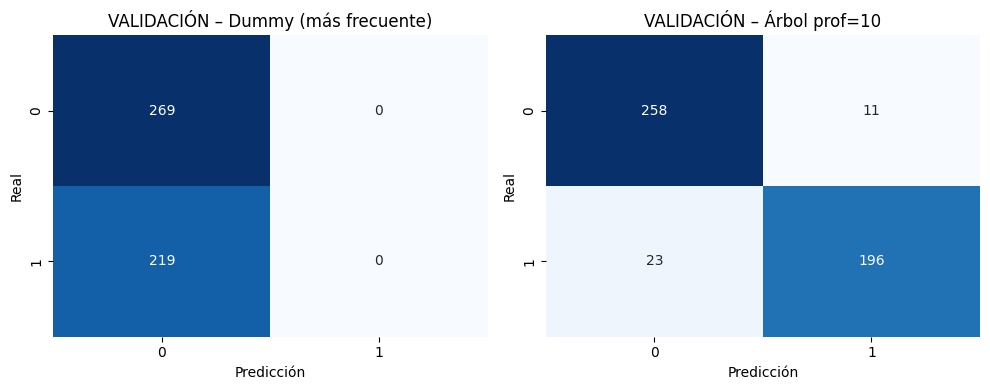

In [7]:
def metricas_clf(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "Costo": COSTO_FN * int(fn) + COSTO_FP * int(fp)}


modelos_clf = {
    "Dummy (más frecuente)": DummyClassifier(strategy="most_frequent"),
    "Árbol prof=3": pipe(DecisionTreeClassifier(max_depth=3, random_state=SEMILLA)),
    "Árbol prof=5": pipe(DecisionTreeClassifier(max_depth=5, random_state=SEMILLA)),
    "Árbol prof=10": pipe(DecisionTreeClassifier(max_depth=10, random_state=SEMILLA)),
    "KNN k=5": pipe(KNeighborsClassifier(n_neighbors=5)),
    "KNN k=15": pipe(KNeighborsClassifier(n_neighbors=15)),
    "GaussianNB": pipe(GaussianNB()),
}

filas = []
for nombre, m in modelos_clf.items():
    m.fit(X_train, yc_train)
    filas.append({"Modelo": nombre, **metricas_clf(yc_val, m.predict(X_val))})
tabla_clf_val = pd.DataFrame(filas).set_index("Modelo")

print("--- CLASIFICACIÓN: resultados en VALIDACIÓN ---")
display(tabla_clf_val)

candidatos = tabla_clf_val.drop(index="Dummy (más frecuente)")
# Criterio: menor costo total (5*FN + 1*FP) en VALIDACIÓN; si hay empate, mayor F1 en validación.
# (El desempate se fija de antemano para no depender del orden en que figuran los modelos.)
nombre_clf = candidatos.sort_values(["Costo", "F1"], ascending=[True, False]).index[0]
empatados = candidatos.index[candidatos["Costo"] == candidatos["Costo"].min()].tolist()
print(f"\nClasificador seleccionado (menor costo en validación; desempate por F1): {nombre_clf}")
if len(empatados) > 1:
    print("Modelos empatados en costo:", empatados)

# Matrices de confusión en VALIDACIÓN (identificadas como tales)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, nombre in zip(ax, ["Dummy (más frecuente)", nombre_clf]):
    sns.heatmap(confusion_matrix(yc_val, modelos_clf[nombre].predict(X_val), labels=[0, 1]),
                annot=True, fmt="d", cmap="Blues", cbar=False, ax=a)
    a.set_title(f"VALIDACIÓN – {nombre}"); a.set_xlabel("Predicción"); a.set_ylabel("Real")
plt.tight_layout(); plt.show()

**Interpretación.** Con clases balanceadas, el `DummyClassifier` obtiene un *accuracy* cercano al 50 %, con *recall* 0
si predice siempre "no crítico" (no detecta ningún equipo urgente). Un clasificador útil debe superar ese piso en
*recall* y en costo total. Se prefiere el modelo con menor costo porque un falso negativo es más grave que un falso
positivo (supuesto 5:1). Si cambiara esa relación de costos, podría elegirse otro modelo.

## 9. Evaluación final en test (una sola vez)

Recién ahora se usa el test, **sin modificar** ningún modelo, hiperparámetro ni umbral.

In [8]:
modelo_reg_final = modelos_reg[nombre_reg]
modelo_clf_final = modelos_clf[nombre_clf]
baseline_reg = modelos_reg["Dummy (media)"]
baseline_clf = modelos_clf["Dummy (más frecuente)"]

pred_reg_test = modelo_reg_final.predict(X_test)
pred_base_reg_test = baseline_reg.predict(X_test)

tabla_reg_test = pd.DataFrame([
    {"Modelo": "DummyRegressor (baseline)", **metricas_reg(yr_test, pred_base_reg_test)},
    {"Modelo": f"Regresor seleccionado ({nombre_reg})", **metricas_reg(yr_test, pred_reg_test)},
]).set_index("Modelo")
print("--- REGRESIÓN: resultados finales en TEST ---")
display(tabla_reg_test)

mae_m = tabla_reg_test.iloc[1]["MAE (USD)"]; mae_b = tabla_reg_test.iloc[0]["MAE (USD)"]
r2_m = tabla_reg_test.iloc[1]["R2"]
print(f"\nInterpretación: en promedio el modelo se equivoca en USD {mae_m:,.0f} por equipo "
      f"(el baseline, USD {mae_b:,.0f}); reduce el error en {100*(1-mae_m/mae_b):.1f} %.")
print(f"R² = {r2_m:.3f}: explica {100*r2_m:.1f} % de la variación DENTRO de esta simulación. "
      f"Un R² alto aquí no implica capacidad real, porque los datos salen de una fórmula.")

--- REGRESIÓN: resultados finales en TEST ---

Interpretación: en promedio el modelo se equivoca en USD 20,619 por equipo (el baseline, USD 71,057); reduce el error en 71.0 %.
R² = 0.882: explica 88.2 % de la variación DENTRO de esta simulación. Un R² alto aquí no implica capacidad real, porque los datos salen de una fórmula.


,MAE (USD),RMSE (USD),R2
Modelo,,,
DummyRegressor (baseline),"71,057.0337","92,757.6839",-0.0011
Regresor seleccionado (KNN k=15),"20,618.6939","31,841.4561",0.8820


Residuo medio: USD -132 | mediana: USD -6290
Subestima (residuo > 0): 35.7 % de los casos | Sobreestima (residuo < 0): 64.3 %
Convención: residuo positivo = el real supera al predicho (el modelo SUBESTIMA); negativo = SOBREESTIMA.

--- 10 mayores errores absolutos en test ---


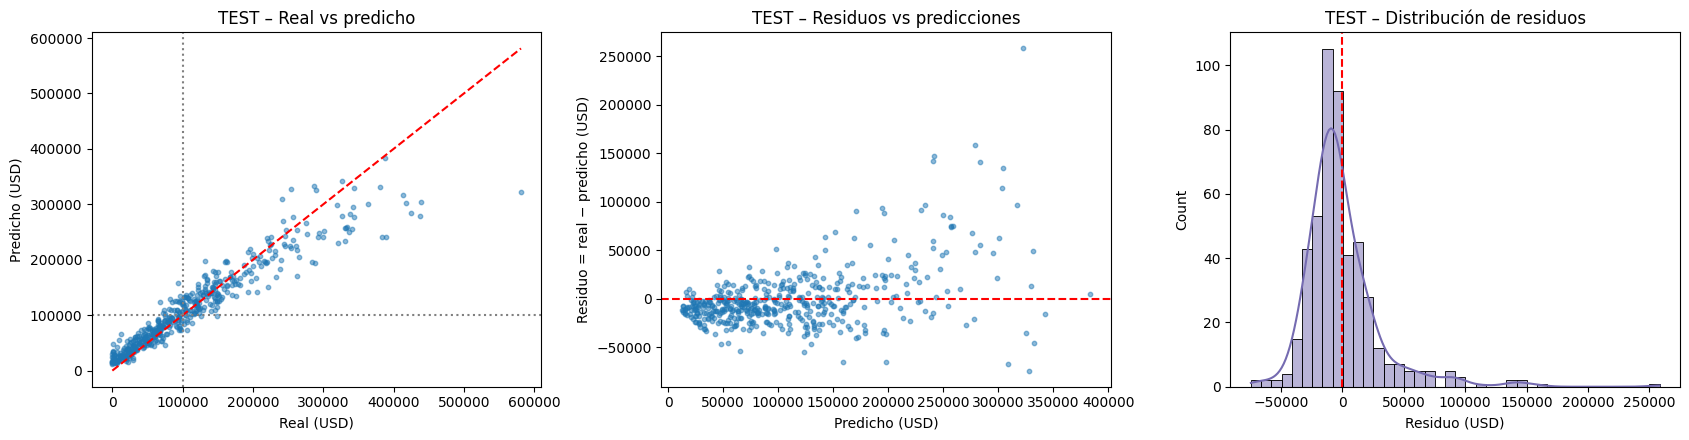

,Real_USD,Predicho_USD,Residuo_USD,Error_Absoluto_USD,tipo_equipo,provincia,meses_inactividad,anio_fabricacion,estado_motor
1756,"581,198.3900","322,952.9000","258,245.4900","258,245.4900",Topadora,Salta,112,2026,Requiere_Reparacion
762,"438,205.6700","279,247.9400","158,957.7300","158,957.7300",Topadora,Salta,113,2023,Funcional
1452,"388,852.3800","241,485.0200","147,367.3600","147,367.3600",Motoniveladora,Santa Fe,79,2026,Averia_Grave
2209,"383,135.9100","241,035.7800","142,100.1300","142,100.1300",Motoniveladora,Buenos Aires,91,2025,Requiere_Reparacion
86,"425,100.9600","283,780.2100","141,320.7500","141,320.7500",Motoniveladora,Córdoba,100,2022,Averia_Grave
1591,"439,061.1500","304,163.6900","134,897.4600","134,897.4600",Topadora,Salta,97,2026,Funcional
885,"417,403.2900","303,101.1000","114,302.1900","114,302.1900",Motoniveladora,Salta,112,2018,Averia_Grave
2245,"413,489.8400","316,800.6000","96,689.2400","96,689.2400",Topadora,Santa Fe,104,2021,Requiere_Reparacion
2397,"330,215.8300","233,612.6700","96,603.1600","96,603.1600",Topadora,Buenos Aires,68,2020,Averia_Grave
318,"288,246.4100","194,832.4100","93,414.0000","93,414.0000",Motoniveladora,Salta,101,2013,Requiere_Reparacion


In [9]:
residuos = yr_test.to_numpy() - pred_reg_test       # residuo = real - predicho
errores_test = pd.DataFrame({"Real_USD": yr_test.to_numpy(), "Predicho_USD": pred_reg_test,
                             "Residuo_USD": residuos, "Error_Absoluto_USD": np.abs(residuos)},
                            index=yr_test.index).join(X_test)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(yr_test, pred_reg_test, s=10, alpha=.5)
lim = [0, max(yr_test.max(), pred_reg_test.max())]
ax[0].plot(lim, lim, "r--"); ax[0].axvline(UMBRAL, color="gray", ls=":"); ax[0].axhline(UMBRAL, color="gray", ls=":")
ax[0].set_title("TEST – Real vs predicho"); ax[0].set_xlabel("Real (USD)"); ax[0].set_ylabel("Predicho (USD)")
ax[1].scatter(pred_reg_test, residuos, s=10, alpha=.5)
ax[1].axhline(0, color="r", ls="--"); ax[1].set_title("TEST – Residuos vs predicciones")
ax[1].set_xlabel("Predicho (USD)"); ax[1].set_ylabel("Residuo = real − predicho (USD)")
sns.histplot(residuos, bins=40, kde=True, ax=ax[2], color="#756bb1")
ax[2].axvline(0, color="r", ls="--"); ax[2].set_title("TEST – Distribución de residuos"); ax[2].set_xlabel("Residuo (USD)")
plt.tight_layout(); plt.show()

print("Residuo medio: USD %.0f | mediana: USD %.0f" % (residuos.mean(), np.median(residuos)))
print("Subestima (residuo > 0): %.1f %% de los casos | Sobreestima (residuo < 0): %.1f %%"
      % (100 * (residuos > 0).mean(), 100 * (residuos < 0).mean()))
print("Convención: residuo positivo = el real supera al predicho (el modelo SUBESTIMA); negativo = SOBREESTIMA.")
print("\n--- 10 mayores errores absolutos en test ---")
display(errores_test.sort_values("Error_Absoluto_USD", ascending=False).head(10).round(2))

**Interpretación de residuos.** Si los residuos se reparten alrededor de 0 sin patrón, el modelo no tiene sesgo
sistemático. La dispersión aumenta con la pérdida predicha (**heterocedasticidad**), porque el ruido de la simulación es
**multiplicativo**: los errores más grandes aparecen en los equipos de mayor valor y más meses de inactividad, que
son justamente los más críticos. Los 10 mayores errores muestran qué combinaciones cuestan más predecir.

--- CLASIFICACIÓN: resultados finales en TEST ---


,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Costo
Modelo,,,,,,,,,
DummyClassifier (baseline),0.5512,0.0000,0.0000,0.0000,269,0,219,0,1095
Clasificador seleccionado (Árbol prof=10),0.9037,0.8909,0.8950,0.8929,245,24,23,196,139


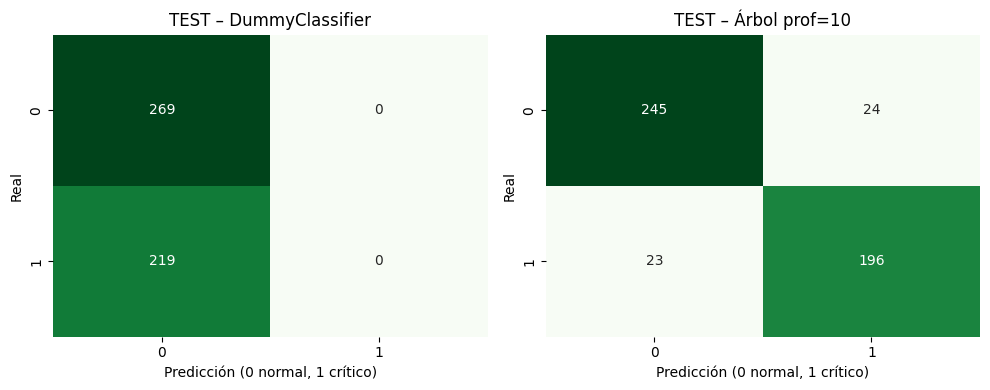

In [10]:
# ----- Clasificación en TEST (baseline y clasificador seleccionado) -----
pred_clf_test = modelo_clf_final.predict(X_test)
pred_base_clf_test = baseline_clf.predict(X_test)

tabla_clf_test = pd.DataFrame([
    {"Modelo": "DummyClassifier (baseline)", **metricas_clf(yc_test, pred_base_clf_test)},
    {"Modelo": f"Clasificador seleccionado ({nombre_clf})", **metricas_clf(yc_test, pred_clf_test)},
]).set_index("Modelo")
print("--- CLASIFICACIÓN: resultados finales en TEST ---")
display(tabla_clf_test)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (t, p) in zip(ax, [("DummyClassifier", pred_base_clf_test), (nombre_clf, pred_clf_test)]):
    sns.heatmap(confusion_matrix(yc_test, p, labels=[0, 1]), annot=True, fmt="d", cmap="Greens", cbar=False, ax=a)
    a.set_title(f"TEST – {t}"); a.set_xlabel("Predicción (0 normal, 1 crítico)"); a.set_ylabel("Real")
plt.tight_layout(); plt.show()

## 10. Comparación integrada: clasificador directo vs regresión + umbral

Se evalúan **los mismos 500 casos de test** (aprox.). Ambos sistemas producen una alerta:
- **Clasificador directo:** predice la clase 0/1.
- **Regresión + umbral:** predice USD y aplica `pred >= 100.000`.

=== TABLA INTEGRADORA (TEST) ===

Costo total en test según la relación de costos (supuestos):


,Accuracy,Precision,Recall,F1,FP,FN,Costo
Sistema,,,,,,,
Clasificador directo,0.9037,0.8909,0.8950,0.8929,24,23,139
Regresión + umbral,0.9344,0.8979,0.9635,0.9295,24,8,64


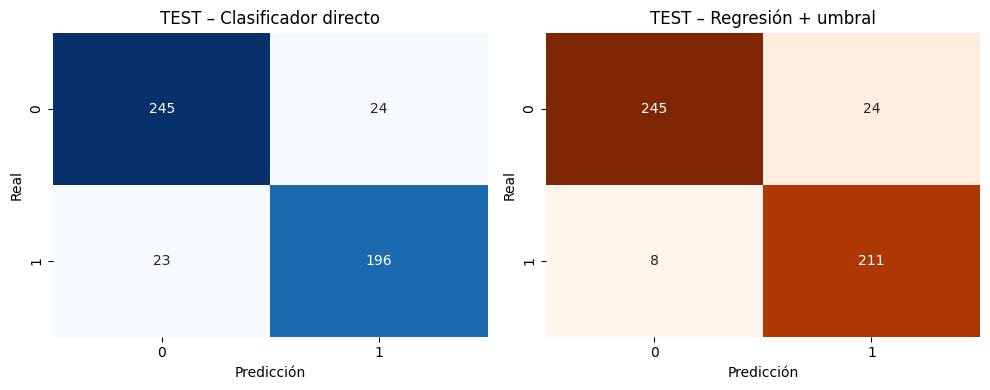

,Directo,Regresión+umbral
Costo FN : FP,,
1 : 1,47,32
3 : 1,93,48
5 : 1,139,64
10 : 1,254,104


In [11]:
alerta_umbral = (pred_reg_test >= UMBRAL).astype(int)
alerta_directa = pred_clf_test

tabla_integradora = pd.DataFrame([
    {"Sistema": "Clasificador directo", **metricas_clf(yc_test, alerta_directa)},
    {"Sistema": "Regresión + umbral", **metricas_clf(yc_test, alerta_umbral)},
]).set_index("Sistema")
print("=== TABLA INTEGRADORA (TEST) ===")
display(tabla_integradora[["Accuracy", "Precision", "Recall", "F1", "FP", "FN", "Costo"]])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (t, p, c) in zip(ax, [("Clasificador directo", alerta_directa, "Blues"), ("Regresión + umbral", alerta_umbral, "Oranges")]):
    sns.heatmap(confusion_matrix(yc_test, p, labels=[0, 1]), annot=True, fmt="d", cmap=c, cbar=False, ax=a)
    a.set_title(f"TEST – {t}"); a.set_xlabel("Predicción"); a.set_ylabel("Real")
plt.tight_layout(); plt.show()

# ----- Sensibilidad a la relación de costos (informativo, no se usa para elegir modelos) -----
filas = []
for r in [1, 3, 5, 10]:
    fila = {"Costo FN : FP": f"{r} : 1"}
    for nombre, p in [("Directo", alerta_directa), ("Regresión+umbral", alerta_umbral)]:
        tn, fp, fn, tp = confusion_matrix(yc_test, p, labels=[0, 1]).ravel()
        fila[nombre] = r * fn + fp
    filas.append(fila)
print("\nCosto total en test según la relación de costos (supuestos):")
display(pd.DataFrame(filas).set_index("Costo FN : FP"))

In [12]:
# ----- Casos cercanos al umbral y 'buen MAE con mala alerta' -----
BANDA = 10_000   # USD: franja descriptiva alrededor del umbral (no es una medida de certeza estadística)
analisis = errores_test.copy()
analisis["Real_critico"] = yc_test.to_numpy()
analisis["Alerta_umbral"] = alerta_umbral
analisis["Alerta_directa"] = alerta_directa
analisis["Distancia_al_umbral"] = (analisis["Predicho_USD"] - UMBRAL).abs()
analisis["Cerca"] = analisis["Distancia_al_umbral"] <= BANDA
analisis["Error_umbral"] = analisis["Alerta_umbral"] != analisis["Real_critico"]
analisis["Error_directo"] = analisis["Alerta_directa"] != analisis["Real_critico"]

resumen = analisis.groupby("Cerca").agg(Casos=("Real_critico", "size"),
                                         Errores_regresion_umbral=("Error_umbral", "sum"),
                                         Errores_directo=("Error_directo", "sum"))
resumen.index = resumen.index.map({True: f"A ≤ USD {BANDA:,} del umbral", False: "Lejos del umbral"})
print("Errores de alerta según cercanía al umbral (TEST):")
display(resumen)

mal_con_buen_mae = analisis[analisis["Error_umbral"] & (analisis["Error_Absoluto_USD"] <= mae_m)]
print(f"\nCasos con alerta INCORRECTA (regresión+umbral) pese a error numérico menor o igual al MAE "
      f"(USD {mae_m:,.0f}): {len(mal_con_buen_mae)} de {int(analisis['Error_umbral'].sum())} errores.")
display(mal_con_buen_mae.sort_values("Distancia_al_umbral")[
    ["Real_USD", "Predicho_USD", "Error_Absoluto_USD", "Real_critico", "Alerta_umbral", "Alerta_directa"]].head(8).round(2))

desacuerdos = int((analisis["Alerta_umbral"] != analisis["Alerta_directa"]).sum())
print(f"\nCasos en que los dos sistemas DISCREPAN: {desacuerdos} de {len(analisis)}")

Errores de alerta según cercanía al umbral (TEST):

Casos con alerta INCORRECTA (regresión+umbral) pese a error numérico menor o igual al MAE (USD 20,619): 12 de 32 errores.

Casos en que los dos sistemas DISCREPAN: 53 de 488


,Casos,Errores_regresion_umbral,Errores_directo
Cerca,,,
Lejos del umbral,440,16,31
"A ≤ USD 10,000 del umbral",48,16,16


,Real_USD,Predicho_USD,Error_Absoluto_USD,Real_critico,Alerta_umbral,Alerta_directa
996,"89,876.9000","101,289.5600","11,412.6600",0,1,1
107,"96,852.5900","102,560.6000","5,708.0100",0,1,1
1268,"110,586.1900","96,318.5300","14,267.6600",1,0,1
2295,"95,309.1500","105,403.0300","10,093.8800",0,1,0
1935,"99,084.3300","106,594.0100","7,509.6800",0,1,1
1579,"98,834.9500","107,756.5800","8,921.6300",0,1,1
2333,"106,863.0400","90,839.7200","16,023.3200",1,0,1
284,"91,815.1800","109,438.9700","17,623.7900",0,1,1


### Lectura de resultados: respuestas a las preguntas del informe (4.3)

La celda siguiente calcula las respuestas **con los números de esta ejecución** (no hay valores escritos a mano),
de modo que las interpretaciones siempre coinciden con las tablas.

In [13]:
d, r = tabla_integradora.loc["Clasificador directo"], tabla_integradora.loc["Regresión + umbral"]
mejor_recall = "Regresión + umbral" if r["Recall"] >= d["Recall"] else "Clasificador directo"
mejor_costo = "Regresión + umbral" if r["Costo"] <= d["Costo"] else "Clasificador directo"
cerca = analisis[analisis["Cerca"]]
n_mal_buen_mae = len(mal_con_buen_mae); n_err = int(analisis["Error_umbral"].sum())

print("1) ¿La regresión supera al baseline?")
print(f"   Sí. MAE {mae_m:,.0f} vs {mae_b:,.0f} USD del DummyRegressor (reduce {100*(1-mae_m/mae_b):.1f} %); R² {r2_m:.3f} vs {tabla_reg_test.iloc[0]['R2']:.3f}.")
print("2) ¿Qué significa el MAE aquí?")
print(f"   La estimación de pérdida se desvía en promedio USD {mae_m:,.0f} por equipo: {100*mae_m/UMBRAL:.0f} % del umbral y {100*mae_m/yr_test.mean():.0f} % de la pérdida media del test (USD {yr_test.mean():,.0f}).")
print("3) ¿Qué sistema detecta mejor los casos críticos?")
print(f"   {mejor_recall}: recall {max(r['Recall'], d['Recall']):.3f} (FN: regresión+umbral {int(r['FN'])} vs directo {int(d['FN'])}).")
print("4) ¿Qué errores son más costosos?")
print(f"   Los falsos negativos (costo relativo {COSTO_FN}:{COSTO_FP}): un equipo crítico queda sin atender y sigue acumulando pérdida. "
      f"Costo total en test: directo {int(d['Costo'])} vs regresión+umbral {int(r['Costo'])}.")
print("5) ¿Qué pasa con los casos cercanos al umbral?")
print(f"   {len(cerca)} de {len(analisis)} casos tienen estimación a ≤ USD {BANDA:,} del umbral y concentran {int(cerca['Error_umbral'].sum())} de los {n_err} errores de regresión+umbral "
      f"({100*cerca['Error_umbral'].mean():.0f} % de error dentro de la franja vs {100*analisis[~analisis['Cerca']]['Error_umbral'].mean():.0f} % fuera).")
print("6) ¿Es posible un buen MAE y una mala clasificación?")
print(f"   Sí: {n_mal_buen_mae} de los {n_err} errores de alerta de regresión+umbral tuvieron un error numérico menor o igual al MAE (USD {mae_m:,.0f}); cruzaron el umbral por poco.")
print("7) ¿Qué sistema se recomienda?")
print(f"   {mejor_costo} (menor costo total y menos FN), complementado con revisión manual de los {desacuerdos} casos de discrepancia y de los casos cercanos al umbral.")
print("8) ¿Cuándo no usar la solución?")
print("   Con equipos reales (datos simulados), sin validar umbral y costos con datos observados, como dictamen pericial, o con combinaciones fuera de los rangos de entrenamiento.")

1) ¿La regresión supera al baseline?
   Sí. MAE 20,619 vs 71,057 USD del DummyRegressor (reduce 71.0 %); R² 0.882 vs -0.001.
2) ¿Qué significa el MAE aquí?
   La estimación de pérdida se desvía en promedio USD 20,619 por equipo: 21 % del umbral y 18 % de la pérdida media del test (USD 111,811).
3) ¿Qué sistema detecta mejor los casos críticos?
   Regresión + umbral: recall 0.963 (FN: regresión+umbral 8 vs directo 23).
4) ¿Qué errores son más costosos?
   Los falsos negativos (costo relativo 5:1): un equipo crítico queda sin atender y sigue acumulando pérdida. Costo total en test: directo 139 vs regresión+umbral 64.
5) ¿Qué pasa con los casos cercanos al umbral?
   48 de 488 casos tienen estimación a ≤ USD 10,000 del umbral y concentran 16 de los 32 errores de regresión+umbral (33 % de error dentro de la franja vs 4 % fuera).
6) ¿Es posible un buen MAE y una mala clasificación?
   Sí: 12 de los 32 errores de alerta de regresión+umbral tuvieron un error numérico menor o igual al MAE (USD

## 11. Guardado de modelos y verificación

Se guardan **solo los dos Pipelines oficiales** y un archivo `metadata.json` con versiones, semilla, umbral,
categorías, rangos y métricas. La aplicación Flask lee ese archivo para usar exactamente las mismas reglas.

In [14]:
ruta_reg = DIR_MODELOS / "modelo_regresion_perdidas.joblib"
ruta_clf = DIR_MODELOS / "modelo_clasificacion_perdidas.joblib"
joblib.dump(modelo_reg_final, ruta_reg)
joblib.dump(modelo_clf_final, ruta_clf)

metadata = {
    "generado": date.today().isoformat(),
    "datos_simulados": True,
    "semilla": SEMILLA,
    "umbral_usd": UMBRAL,
    "regla_umbral": "perdida_critica = perdida_economica_usd >= umbral_usd",
    "predictores": PREDICTORES,
    "categorias": {"tipo_equipo": TIPOS, "provincia": PROVINCIAS, "estado_motor": ESTADOS},
    "rangos": {"meses_inactividad": [MESES_MIN, MESES_MAX], "anio_fabricacion": [ANIO_MIN, ANIO_MAX]},
    "costos_relativos": {"falso_negativo": COSTO_FN, "falso_positivo": COSTO_FP},
    "modelo_regresion": nombre_reg,
    "modelo_clasificacion": nombre_clf,
    "versiones": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                  "scikit-learn": sklearn.__version__, "joblib": joblib.__version__},
    "filas": {"train": len(X_train), "validation": len(X_val), "test": len(X_test)},
    "metricas_test": {
        "regresion": {k: float(v) for k, v in tabla_reg_test.iloc[1].items()},
        "baseline_regresion": {k: float(v) for k, v in tabla_reg_test.iloc[0].items()},
        "clasificador_directo": {k: float(v) for k, v in tabla_integradora.loc["Clasificador directo"].items()},
        "regresion_mas_umbral": {k: float(v) for k, v in tabla_integradora.loc["Regresión + umbral"].items()},
    },
}
with open(DIR_MODELOS / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

# ----- Verificación: recargar desde disco y comprobar que predice igual que en memoria -----
reg_cargado = joblib.load(ruta_reg)
clf_cargado = joblib.load(ruta_clf)
assert np.allclose(reg_cargado.predict(X_test), pred_reg_test), "El regresor cargado difiere"
assert (clf_cargado.predict(X_test) == pred_clf_test).all(), "El clasificador cargado difiere"
assert np.isfinite(reg_cargado.predict(X_test)).all()
assert set(np.unique(clf_cargado.predict(X_test))) <= {0, 1}

caso = pd.DataFrame([{"tipo_equipo": "Excavadora", "provincia": "Córdoba", "meses_inactividad": 36,
                      "anio_fabricacion": 2015, "estado_motor": "Requiere_Reparacion"}])
print("Modelos guardados y verificados:")
print(" -", ruta_reg.relative_to(RAIZ)); print(" -", ruta_clf.relative_to(RAIZ)); print(" -", (DIR_MODELOS / 'metadata.json').relative_to(RAIZ))
print(f"\nCaso de ejemplo -> pérdida estimada: USD {reg_cargado.predict(caso)[0]:,.2f} | clase directa: {int(clf_cargado.predict(caso)[0])}")

Modelos guardados y verificados:
 - modelos/modelo_regresion_perdidas.joblib
 - modelos/modelo_clasificacion_perdidas.joblib
 - modelos/metadata.json

Caso de ejemplo -> pérdida estimada: USD 84,583.83 | clase directa: 0


## Conclusiones y limitaciones

- Los datos son **simulados**; las métricas describen el desempeño dentro de la simulación y **no prueban capacidad predictiva real**.
- El umbral (USD 100.000) y los costos (FN = 5, FP = 1) son **supuestos** que requieren validación externa para un uso operativo.
- Los modelos se eligieron con validación; el test se usó una sola vez, al final.
- La aplicación es una **demostración experimental** y no reemplaza una evaluación pericial.